In [ ]:
# CELLULE 1: EXTRACTION AVEC REGEX UNIQUEMENT (VERSION CORRIGÉE)
import pandas as pd
import re
import logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

class TunisianRealEstateRegexExtractor:
    """Extracteur regex pour l'immobilier tunisien"""

    def __init__(self):
        self.patterns = {
            'price': self._build_price_patterns(),
            'codeP': self._build_postal_code_patterns(),
            'superficie_habitale': self._build_surface_patterns(),
            'salle_de_bain': self._build_bathroom_patterns(),
            'climatisation': self._build_clim_patterns(),
            'tel': self._build_phone_patterns(),
            'gouvernorat': self._build_gouvernorat_patterns()
        }

        self.default_values = {
            'climatisation': 'non',
            'salle_de_bain': 0
        }

    def _build_price_patterns(self) -> list:
        return [
            (r'(\d+(?:[.,]\d{3})*(?:[.,]\d{2})?)\s*(?:DT|dinar|TND|دينار)\b', 1),
            (r'prix\s*:?\s*(\d+(?:[.,]\d{3})*)\s*(?:DT|dinar)?', 1),
            (r'(\d+(?:[.,]\d{3})*)\s*(?:millions?|milles?)\s*(?:DT|dinar)?', 1),
            (r'vente\s*(\d+(?:[.,]\d{3})*)', 1),
        ]

    def _build_postal_code_patterns(self) -> list:
        return [
            (r'\b(1[0-2]|2[0-1]|3[0-4]|4[0-9]|5[0-9]|6[0-9]|7[0-9]|8[0-9]|9[0-9])\d{2}\b', 0),
            (r'code postal\s*:?\s*(\d{4})', 1),
            (r'cp\s*:?\s*(\d{4})', 1),
        ]

    def _build_surface_patterns(self) -> list:
        return [
            (r'(\d+(?:[.,]\d+)?)\s*m[²2]', 1),
            (r'surface\s*:?\s*(\d+(?:[.,]\d+)?)\s*(?:m[²2])?', 1),
            (r'superficie\s*:?\s*(\d+(?:[.,]\d+)?)\s*(?:m[²2])?', 1),
            (r'dimensions?\s*(\d+(?:[.,]\d+)?)\s*[x×]\s*(\d+(?:[.,]\d+)?)', (1, 2)),
        ]

    def _build_bathroom_patterns(self) -> list:
        return [
            (r'(\d+)\s*(?:salle de bain|salles de bain|sdb|bathroom)', 1),
            (r'(?:salle de bain|sdb)\s*:?\s*(\d+)', 1),
        ]

    def _build_clim_patterns(self) -> list:
        return [
            r'clim|climatisation|air conditionn[ée]|chauffage réversible|split|ac',
            r'climatisé|climatisée|réversible',
            r'تكييف|مكيف',
        ]

    def _build_phone_patterns(self) -> list:
        return [
            (r'(?:\+216)?[ -]?([259][0-9]{7})', 1),
            (r'tél(?:éphone)?\s*:?\s*(\+216[ -]?[0-9]{8}|[0-9]{8})', 1),
        ]

    def _build_gouvernorat_patterns(self) -> dict:
        return {
            'Tunis': r'\b(tunis|تونس|tunis ville)\b',
            'Ariana': r'\b(ariana|أريانة)\b',
            'Ben Arous': r'\b(ben arous|بن عروس)\b',
            'Manouba': r'\b(manouba|منوبة)\b',
            'Nabeul': r'\b(nabeul|نابل|hammamet)\b',
            'Sousse': r'\b(sousse|سوسة)\b',
            'Sfax': r'\b(sfax|صفاقس)\b',
            'Monastir': r'\b(monastir|المنستير)\b',
            'Mahdia': r'\b(mahdia|المهدية)\b',
            'Bizerte': r'\b(bizerte|بنزرت)\b',
            'Béja': r'\b(béja|beja|باجة)\b',
            'Jendouba': r'\b(jendouba|جندوبة)\b',
            'Le Kef': r'\b(kef|le kef|الكاف)\b',
            'Siliana': r'\b(siliana|سليانة)\b',
            'Kairouan': r'\b(kairouan|القيروان)\b',
            'Kasserine': r'\b(kasserine|القصرين)\b',
            'Sidi Bouzid': r'\b(sidi bouzid|سيدي بوزيد)\b',
            'Zaghouan': r'\b(zaghouan|زغوان)\b',
            'Gabès': r'\b(gabès|gabes|قابس)\b',
            'Médenine': r'\b(médenine|medenine|مدنين)\b',
            'Tataouine': r'\b(tataouine|تطاوين)\b',
            'Gafsa': r'\b(gafsa|قفصة)\b',
            'Tozeur': r'\b(tozeur|توزر)\b',
            'Kébili': r'\b(kébili|kebili|قبلي)\b',
        }

    def extract_price(self, text: str) -> str:
        if not text:
            return None
        for pattern, group_idx in self.patterns['price']:
            match = re.search(pattern, text, re.IGNORECASE)
            if match:
                price_str = match.group(group_idx).replace(',', '').replace('.', '')
                price_str = re.sub(r'[^\d]', '', price_str)
                if price_str:
                    price_int = int(price_str)
                    full_match = match.group(0).lower()
                    if 'million' in full_match:
                        price_int *= 1_000_000
                    elif 'mille' in full_match:
                        price_int *= 1_000
                    return f"{price_int:,} DT".replace(',', ' ')
        return None

    def extract_codeP(self, text: str) -> str:
        if not text:
            return None
        for pattern, group_idx in self.patterns['codeP']:
            match = re.search(pattern, text, re.IGNORECASE)
            if match:
                code = match.group(group_idx) if group_idx > 0 else match.group(0)
                code = re.sub(r'[^\d]', '', code)
                if len(code) == 4 and 1000 <= int(code) <= 9999:
                    return code
        return None

    def extract_superficie(self, text: str) -> str:
        if not text:
            return None
        for pattern, group_idx in self.patterns['superficie_habitale']:
            match = re.search(pattern, text, re.IGNORECASE)
            if match:
                if isinstance(group_idx, tuple):
                    w = float(match.group(group_idx[0]).replace(',', '.'))
                    h = float(match.group(group_idx[1]).replace(',', '.'))
                    surface = w * h
                else:
                    surface = float(match.group(group_idx).replace(',', '.'))
                return f"{surface:.0f} m²"
        return None

    def extract_salle_de_bain(self, text: str) -> int:
        if not text:
            return None
        for pattern, group_idx in self.patterns['salle_de_bain']:
            match = re.search(pattern, text, re.IGNORECASE)
            if match:
                return int(match.group(group_idx))
        return None

    def extract_climatisation(self, text: str) -> str:
        if not text:
            return 'non'
        for pattern in self.patterns['climatisation']:
            if re.search(pattern, text, re.IGNORECASE):
                return 'oui'
        return 'non'

    def extract_tel(self, text: str) -> str:
        if not text:
            return None
        for pattern, group_idx in self.patterns['tel']:
            match = re.search(pattern, text, re.IGNORECASE)
            if match:
                phone = match.group(group_idx) if group_idx > 0 else match.group(0)
                phone = re.sub(r'[^\d+]', '', phone)
                if phone.startswith('+216'):
                    phone = phone[4:]
                if len(phone) >= 8:
                    return f"+216 {phone[:2]} {phone[2:5]} {phone[5:7]} {phone[7:11]}"
        return None

    def extract_gouvernorat(self, text: str) -> str:
        if not text:
            return None
        text_lower = text.lower()
        for gouvernorat, pattern in self.patterns['gouvernorat'].items():
            if re.search(pattern, text_lower):
                return gouvernorat
        return None

    def extract_all(self, description: str) -> dict:
        """Extraction avec regex seulement"""
        if not description or len(description.strip()) < 5:
            return {}

        description = str(description)

        return {
            'price': self.extract_price(description),
            'codeP': self.extract_codeP(description),
            'superficie_habitale': self.extract_superficie(description),
            'salle_de_bain': self.extract_salle_de_bain(description),
            'climatisation': self.extract_climatisation(description),
            'tel': self.extract_tel(description),
            'gouvernorat': self.extract_gouvernorat(description),
        }

# Charger les données
print("="*60)
print("EXTRACTION PAR REGEX - IMMOBILIER TUNISIEN")
print("="*60)

# Charger votre fichier nettoyé
cv = pd.read_excel('cv_nettoye.xlsx')
print(f"✅ Fichier chargé: {len(cv)} lignes, {len(cv.columns)} colonnes")

# Liste des colonnes à extraire
colonnes_a_extraire = ['price', 'codeP', 'superficie_habitale', 'salle_de_bain', 'climatisation', 'tel', 'gouvernorat']

# Créer uniquement les colonnes qui n'existent pas déjà
for col in colonnes_a_extraire:
    if col not in cv.columns:
        cv[col] = None
        print(f"  + Colonne ajoutée: {col}")
    else:
        print(f"  ✓ Colonne existante: {col}")

# Initialiser l'extracteur
extractor = TunisianRealEstateRegexExtractor()

# Appliquer l'extraction regex (seulement sur les lignes où les valeurs sont vides)
print("\n🔍 Extraction en cours...")
compteur_extractions = {col: 0 for col in colonnes_a_extraire}

for idx, row in cv.iterrows():
    description = row.get('description', '')
    if pd.notna(description):
        extracted = extractor.extract_all(description)
        for field, value in extracted.items():
            # Ne remplacer que si la valeur est actuellement vide (NaN)
            if value is not None and pd.isna(cv.at[idx, field]):
                cv.at[idx, field] = value
                compteur_extractions[field] += 1

# Statistiques
print("\n📊 STATISTIQUES EXTRACTION REGEX:")
for col in colonnes_a_extraire:
    nb_extraits = cv[col].notna().sum()
    pct = (nb_extraits / len(cv)) * 100
    nouvelles = compteur_extractions[col]
    print(f"  {col:20}: {nb_extraits}/{len(cv)} ({pct:.1f}%) - {nouvelles} nouvelles extractions")

# Aperçu
print("\n📝 APERÇU DES RÉSULTATS (10 premières lignes):")
cols_affichage = ['description', 'price', 'superficie_habitale', 'gouvernorat', 'climatisation', 'salle_de_bain']
cols_existantes = [c for c in cols_affichage if c in cv.columns]
if cols_existantes:
    print(cv[cols_existantes].head(10).to_string())
else:
    print("Aucune colonne d'affichage trouvée")

# Sauvegarder
cv.to_excel('cv_avec_regex.xlsx', index=False)
print("\n✅ Résultats sauvegardés dans 'cv_avec_regex.xlsx'")

# Afficher un résumé des colonnes maintenant disponibles
print("\n📋 COLONNES DISPONIBLES APRÈS EXTRACTION:")
for col in colonnes_a_extraire:
    if col in cv.columns:
        non_nuls = cv[col].notna().sum()
        print(f"  • {col}: {non_nuls} valeurs non nulles")

EXTRACTION PAR REGEX - IMMOBILIER TUNISIEN
✅ Fichier chargé: 77826 lignes, 22 colonnes
  ✓ Colonne existante: price
  ✓ Colonne existante: codeP
  + Colonne ajoutée: superficie_habitale
  ✓ Colonne existante: salle_de_bain
  ✓ Colonne existante: climatisation
  ✓ Colonne existante: tel
  ✓ Colonne existante: gouvernorat

🔍 Extraction en cours...


/tmp/ipykernel_2179/1660853624.py:234: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '+216 54 327 17 1' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  cv.at[idx, field] = value
/tmp/ipykernel_2179/1660853624.py:234: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1190' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  cv.at[idx, field] = value



📊 STATISTIQUES EXTRACTION REGEX:
  price               : 58581/77826 (75.3%) - 19809 nouvelles extractions
  codeP               : 5606/77826 (7.2%) - 5606 nouvelles extractions
  superficie_habitale : 39506/77826 (50.8%) - 39506 nouvelles extractions
  salle_de_bain       : 51457/77826 (66.1%) - 172 nouvelles extractions
  climatisation       : 64115/77826 (82.4%) - 63976 nouvelles extractions
  tel                 : 30561/77826 (39.3%) - 30561 nouvelles extractions
  gouvernorat         : 19433/77826 (25.0%) - 17031 nouvelles extractions

📝 APERÇU DES RÉSULTATS (10 premières lignes):
                                                                                                                                                                                                                                                                                              description              price superficie_habitale gouvernorat climatisation salle_de_bain
0                            

In [ ]:
# ====================================================
# PARTIE: CORRECTION SUPERFICIE + AJOUT CHAUFFAGE/CUISINE
# ====================================================

print("\n" + "="*60)
print("AJOUT DES NOUVELLES FEATURES (CHAUFFAGE, CUISINE)")
print("="*60)

# 1. CORRECTION DE LA COLONNE superficie_habitale
if 'superficie_habitable' in cv.columns:
    print("\n📐 Correction de la colonne superficie_habitale...")

    # Avant correction
    avant_superficie = cv['superficie_habitale'].notna().sum()
    print(f"  Avant: {avant_superficie}/{len(cv)} valeurs non nulles")

    # Remplir les vides de superficie_habitale avec superficie_habitable
    cv['superficie_habitale'] = cv['superficie_habitale'].fillna(cv['superficie_habitable'])

    # Après correction
    apres_superficie = cv['superficie_habitale'].notna().sum()
    nouvelles = apres_superficie - avant_superficie
    print(f"  Après: {apres_superficie}/{len(cv)} valeurs non nulles (+{nouvelles} nouvelles)")

    # Supprimer l'ancienne colonne superficie_habitable
    cv = cv.drop(columns=['superficie_habitable'])
    print("  ✓ Colonne 'superficie_habitable' supprimée")
else:
    print("  ⚠️ Colonne 'superficie_habitable' non trouvée")

# 2. FONCTIONS POUR EXTRAIRE CHAUFFAGE ET CUISINE
def extract_chauffage(description):
    """Extraire la présence de chauffage dans la description"""
    if pd.isna(description):
        return 'non'

    text = str(description).lower()

    # Mots-clés pour chauffage
    chauffage_keywords = [
        'chauffage', 'chauffé', 'chauffe', 'radiateur', 'radiateurs',
        'chauffage central', 'chauffage réversible', 'chauffage au sol',
        'poêle', 'cheminée', 'fournaise', 'calorifère',
        'thermostat', 'chauffant', 'chauffante'
    ]

    for keyword in chauffage_keywords:
        if keyword in text:
            return 'oui'
    return 'non'

def extract_cuisine(description):
    """Extraire la présence de cuisine équipée/aménagée"""
    if pd.isna(description):
        return 'non'

    text = str(description).lower()

    # Mots-clés pour cuisine
    cuisine_keywords = [
        'cuisine équipée', 'cuisine aménagée', 'cuisine semi-équipée',
        'cuisine américaine', 'cuisine moderne', 'cuisine fonctionnelle',
        'plan de travail', 'meuble de cuisine', 'armoire de cuisine',
        'plaque', 'four', 'hotte', 'réfrigérateur', 'lave-vaisselle',
        'micro-ondes', 'cuisinière', 'gazinière'
    ]

    # Si la description contient ces mots, c'est une cuisine équipée
    for keyword in cuisine_keywords:
        if keyword in text:
            return 'oui'

    # Vérifier si le mot "cuisine" est présent sans être "non équipée"
    if 'cuisine' in text:
        if 'non équipée' not in text and 'non-equipée' not in text:
            return 'oui'

    return 'non'

# 3. APPLIQUER L'EXTRACTION
print("\n🍳 Extraction de la feature 'cuisine'...")
cv['cuisine'] = cv['description'].apply(extract_cuisine)
nb_cuisine = (cv['cuisine'] == 'oui').sum()
print(f"  ✓ Cuisine: {nb_cuisine}/{len(cv)} ({nb_cuisine/len(cv)*100:.1f}%)")

print("\n🔥 Extraction de la feature 'chauffage'...")
cv['chauffage'] = cv['description'].apply(extract_chauffage)
nb_chauffage = (cv['chauffage'] == 'oui').sum()
print(f"  ✓ Chauffage: {nb_chauffage}/{len(cv)} ({nb_chauffage/len(cv)*100:.1f}%)")

# 4. VÉRIFICATION ET APERÇU
print("\n" + "="*60)
print("APERÇU DES NOUVELLES COLONNES")
print("="*60)

cols_afficher = ['description', 'superficie_habitale', 'cuisine', 'chauffage']
cols_exist = [c for c in cols_afficher if c in cv.columns]

print(cv[cols_exist].head(10).to_string())

# 5. STATISTIQUES FINALES
print("\n" + "="*60)
print("STATISTIQUES FINALES")
print("="*60)
print(f"✓ superficie_habitale: {cv['superficie_habitale'].notna().sum()} valeurs")
print(f"✓ cuisine: {cv['cuisine'].value_counts().to_dict()}")
print(f"✓ chauffage: {cv['chauffage'].value_counts().to_dict()}")




AJOUT DES NOUVELLES FEATURES (CHAUFFAGE, CUISINE)

📐 Correction de la colonne superficie_habitale...
  Avant: 39506/77826 valeurs non nulles
  Après: 39585/77826 valeurs non nulles (+79 nouvelles)
  ✓ Colonne 'superficie_habitable' supprimée

🍳 Extraction de la feature 'cuisine'...
  ✓ Cuisine: 24919/77826 (32.0%)

🔥 Extraction de la feature 'chauffage'...
  ✓ Chauffage: 11742/77826 (15.1%)

APERÇU DES NOUVELLES COLONNES
                                                                                                                                                                                                                                                                                              description superficie_habitale cuisine chauffage
0                                                                                                                                                       Superficie   105 m2 Prix   270 MD REF   TN732 Re servez votre visite et obtenez toutes

TABLEAU DES VALEURS MANQUANTES


,Colonne,Nb valeurs manquantes,Pourcentage (%)
9,other_data,74807,96.120000
5,fonds,73396,94.310000
2,codeP,72220,92.800000
6,gouvernorat,58393,75.030000
14,tel,47265,60.730000
13,superficie_terrain,39123,50.270000
16,superficie_habitale,38241,49.140000
12,salle_de_bain,26369,33.880000
8,nbpiece,20882,26.830000
10,price,19245,24.730000


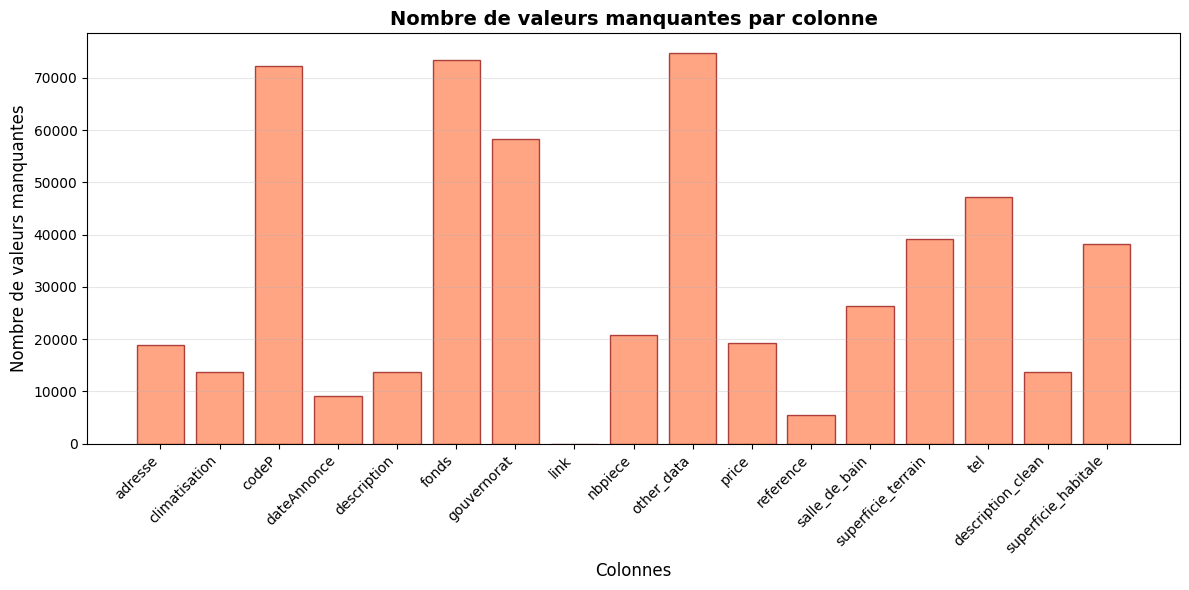

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
valeurs_manquantes = cv.isnull().sum()
valeurs_manquantes = valeurs_manquantes[valeurs_manquantes > 0]
total_lignes = len(cv)

# Créer le tableau
tableau_manquantes = pd.DataFrame({
    'Colonne': valeurs_manquantes.index,
    'Nb valeurs manquantes': valeurs_manquantes.values,
    'Pourcentage (%)': (valeurs_manquantes.values / total_lignes * 100).round(2)
})
tableau_manquantes = tableau_manquantes.sort_values('Nb valeurs manquantes', ascending=False)

# Afficher le tableau avec style (pour notebook)
from IPython.display import display

print("TABLEAU DES VALEURS MANQUANTES")

display(tableau_manquantes.style.background_gradient(cmap='Reds', subset=['Nb valeurs manquantes', 'Pourcentage (%)']))

# Graphique
plt.figure(figsize=(12, 6))
plt.bar(valeurs_manquantes.index, valeurs_manquantes.values, color='coral', edgecolor='darkred', alpha=0.7)
plt.xlabel('Colonnes', fontsize=12)
plt.ylabel('Nombre de valeurs manquantes', fontsize=12)
plt.title('Nombre de valeurs manquantes par colonne', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:
# Version simplifiée pour extraire les équipements principaux
import re

def extraire_equipements(description):
    """Extrait les équipements principaux de la description"""
    if pd.isna(description):
        return {
            'jardin': 'non', 'parking': 'non', 'piscine': 'non',
            'terrasse': 'non',  'vue_mer': 'non',
             'ascenseur': 'non', 'climatisation': 'non'
        }

    text = str(description).lower()

    return {
        'jardin': 'oui' if re.search(r'\bjardin\b|\bespace vert\b', text) else 'non',
        'parking': 'oui' if re.search(r'\bparking\b|\bgarage\b|\babri de voiture\b', text) else 'non',
        'piscine': 'oui' if re.search(r'\bpiscine\b|\bswimming pool\b', text) else 'non',
        'terrasse': 'oui' if re.search(r'\bterrasse\b', text) else 'non',
        'vue_mer': 'oui' if re.search(r'\bvue mer\b|\bface mer\b', text) else 'non',
        'ascenseur': 'oui' if re.search(r'\bascenseur\b', text) else 'non',
        'climatisation': 'oui' if re.search(r'\bclim\b|\bclimatisation\b|\bsplit\b', text) else 'non'
    }

# Appliquer l'extraction
print("Extraction des équipements...")
equipements_df = cv['description'].apply(extraire_equipements).apply(pd.Series)

# Ajouter au dataframe
for col in equipements_df.columns:
    if col not in cv.columns:
        cv[col] = equipements_df[col]
        print(f"  + {col} ajoutée")

# Afficher les statistiques
print("\nStatistiques des équipements:")
for col in equipements_df.columns:
    nb = (cv[col] == 'oui').sum()
    print(f"  {col}: {nb}/{len(cv)} ({nb/len(cv)*100:.1f}%)")



Extraction des équipements...
  + jardin ajoutée
  + parking ajoutée
  + piscine ajoutée
  + terrasse ajoutée
  + vue_mer ajoutée
  + ascenseur ajoutée

Statistiques des équipements:
  jardin: 10973/77826 (14.1%)
  parking: 15116/77826 (19.4%)
  piscine: 6823/77826 (8.8%)
  terrasse: 10930/77826 (14.0%)
  vue_mer: 654/77826 (0.8%)
  ascenseur: 2456/77826 (3.2%)
  climatisation: 47667/77826 (61.2%)


In [ ]:
# Version simplifiée - Features essentielles
print("\n" + "="*60)
print("EXTRACTION SIMPLIFIÉE DEPUIS other_data")
print("="*60)

if 'other_data' in cv.columns:

    # Fonction d'extraction simplifiée
    def extraire_features_simple(text):
        if pd.isna(text):
            return {}

        text = str(text).lower()

        return {
            'jardin': 'oui' if any(k in text for k in ['jardin', 'espace vert']) else 'non',
            'parking': 'oui' if any(k in text for k in ['parking', 'garage', 'abri de voiture', 'stationnement']) else 'non',
            'piscine': 'oui' if any(k in text for k in ['piscine', 'jacuzzi', 'spa']) else 'non',
            'terrasse': 'oui' if any(k in text for k in ['terrasse', 'balcon', 'patio']) else 'non',
            'climatisation': 'oui' if any(k in text for k in ['climatisation', 'clim', 'split', 'air conditionné']) else 'non',
            'ascenseur': 'oui' if 'ascenseur' in text else 'non',
            'vue_mer': 'oui' if 'vue mer' in text or 'bord de mer' in text else 'non',
        }

    # Créer les colonnes et extraire
    for idx, row in cv.iterrows():
        if pd.notna(row.get('other_data', '')):
            extracted = extraire_features_simple(row['other_data'])
            for feature, value in extracted.items():
                if feature not in cv.columns:
                    cv[feature] = None
                if pd.isna(cv.at[idx, feature]):
                    cv.at[idx, feature] = value

    # Statistiques
    print("\n📊 RÉSULTATS:")
    features = ['jardin', 'parking', 'piscine', 'terrasse', 'climatisation', 'ascenseur',  'vue_mer']
    for feature in features:
        if feature in cv.columns:
            nb = (cv[feature] == 'oui').sum()
            print(f"  {feature}: {nb}/{len(cv)} ({nb/len(cv)*100:.1f}%)")

    print("\n✅ Extraction terminée!")


EXTRACTION SIMPLIFIÉE DEPUIS other_data

📊 RÉSULTATS:
  jardin: 10973/77826 (14.1%)
  parking: 15116/77826 (19.4%)
  piscine: 6823/77826 (8.8%)
  terrasse: 10930/77826 (14.0%)
  climatisation: 47667/77826 (61.2%)
  ascenseur: 2456/77826 (3.2%)
  vue_mer: 654/77826 (0.8%)

✅ Extraction terminée!


TABLEAU DES VALEURS MANQUANTES


,Colonne,Nb valeurs manquantes,Pourcentage (%)
9,other_data,74807,96.120000
5,fonds,73396,94.310000
2,codeP,72220,92.800000
6,gouvernorat,58393,75.030000
14,tel,47265,60.730000
13,superficie_terrain,39123,50.270000
16,superficie_habitale,38241,49.140000
12,salle_de_bain,26369,33.880000
8,nbpiece,20882,26.830000
10,price,19245,24.730000


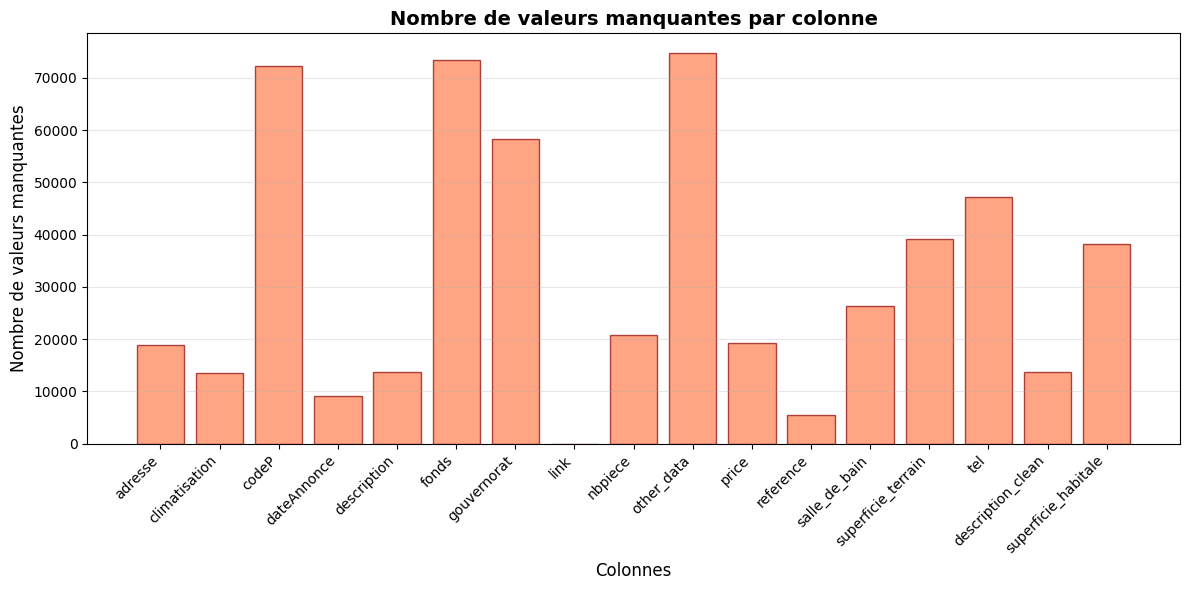

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
valeurs_manquantes = cv.isnull().sum()
valeurs_manquantes = valeurs_manquantes[valeurs_manquantes > 0]
total_lignes = len(cv)

# Créer le tableau
tableau_manquantes = pd.DataFrame({
    'Colonne': valeurs_manquantes.index,
    'Nb valeurs manquantes': valeurs_manquantes.values,
    'Pourcentage (%)': (valeurs_manquantes.values / total_lignes * 100).round(2)
})
tableau_manquantes = tableau_manquantes.sort_values('Nb valeurs manquantes', ascending=False)

# Afficher le tableau avec style (pour notebook)
from IPython.display import display

print("TABLEAU DES VALEURS MANQUANTES")

display(tableau_manquantes.style.background_gradient(cmap='Reds', subset=['Nb valeurs manquantes', 'Pourcentage (%)']))

# Graphique
plt.figure(figsize=(12, 6))
plt.bar(valeurs_manquantes.index, valeurs_manquantes.values, color='coral', edgecolor='darkred', alpha=0.7)
plt.xlabel('Colonnes', fontsize=12)
plt.ylabel('Nombre de valeurs manquantes', fontsize=12)
plt.title('Nombre de valeurs manquantes par colonne', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:
colonnes_a_supprimer = [ 'fonds','codeP','description_clean']  # Remplacez par vos colonnes
cv = cv.drop(columns=colonnes_a_supprimer)

In [ ]:
# ====================================================
# EXTRACTION AMÉLIORÉE + REMPLISSAGE
# ====================================================
import re
import pandas as pd
from tqdm import tqdm

print("\n" + "="*60)
print("EXTRACTION AMÉLIORÉE (GOUVERNORAT & WHATSAPP)")
print("="*60)

# 1. CRÉER LES COLONNES TEMPORAIRES SI ELLES N'EXISTENT PAS
if 'gouvernorat_adresse' not in cv.columns:
    cv['gouvernorat_adresse'] = None
if 'tel_whatsapp' not in cv.columns:
    cv['tel_whatsapp'] = None

# 2. FONCTION AMÉLIORÉE POUR LE GOUVERNORAT (plus de patterns)
def extraire_gouvernorat_ameliore(description):
    if pd.isna(description):
        return None

    text = str(description).lower()

    # Liste étendue des gouvernorats avec leurs variantes
    gouvernorats_dict = {
        'Tunis': ['tunis', 'تونس', 'tunis ville', 'tunis centre', 'el menzah', 'mutuelleville', 'belvédère', 'bardo', 'lafayette', 'bab saadoun', 'bab souika', 'halfaouine', 'djebel jelloud', 'ennasr', 'ennasr 2', 'ennasr 1', 'cité olympique', 'el omrane', 'el ouardia'],
        'Ariana': ['ariana', 'أريانة', 'raoued', 'soukra', 'kalâat el andalous', 'kalaat el andalous', 'sidi thabet', 'et-tadhamen', 'mnihla', 'borj louzir', 'chotrana', 'douar hicher', 'ezzahra', 'sidi slimane'],
        'Ben Arous': ['ben arous', 'بن عروس', 'megrine', 'mohamedia', 'radès', 'rades', 'hammam lif', 'hammam chatt', 'ezzahra', 'bou mhel', 'fouchana', 'mornag', 'nadhour', 'bir el bey', 'el mourouj'],
        'Manouba': ['manouba', 'منوبة', 'douar hicher', 'mornaguia', 'oued ellil', 'el battan', 'borj el amri', 'den den', 'tebourba', 'cités olympiques'],
        'Nabeul': ['nabeul', 'نابل', 'hammamet', 'حمامات', 'dar chaabane', 'korba', 'kelibia', 'قليبية', 'soliman', 'beni khiar', 'el maamoura', 'hammam ghezèze', 'menzel temime', 'takelsa', 'bou argoub'],
        'Sousse': ['sousse', 'سوسة', 'msaken', 'مساكن', 'kalâa kebira', 'kalâa seghira', 'akouda', 'bouficha', 'hammam sousse', 'enfidha', 'zaouiet sousse', 'sidi el hani', 'kondar', 'sahloul'],
        'Sfax': ['sfax', 'صفاقس', 'sakiet eddaïer', 'sakiet ezzit', 'chihia', 'bir ali ben khelifa', 'el ain', 'agra', 'mahrès', 'skhira', 'thyna', 'kerkenah'],
        'Monastir': ['monastir', 'المنستير', 'moknine', 'jemmal', 'bembla', 'ksar hellal', 'sahline', 'teboulba', 'béni hassan', 'ouerdanine', 'sayada', 'lamta'],
        'Mahdia': ['mahdia', 'المهدية', 'jebiniana', 'bou merdes', 'essouassi', 'chebba', 'salakta', 'hajeb el ayoun', 'el jam'],
        'Bizerte': ['bizerte', 'بنزرت', 'mateur', 'menzel bourguiba', 'menzel abderrahmane', 'tinja', 'sejnane', 'ras jebel', 'utique', 'ghezala', 'joumine', 'el alia', 'zarzouna', 'metline'],
        'Béja': ['béja', 'beja', 'باجة', 'testour', 'majaz al bab', 'zahret medien', 'amdoun', 'goubellat'],
        'Jendouba': ['jendouba', 'جندوبة', 'tabarka', 'ain draham', 'fernana', 'ghardimaou', 'oued mliz', 'bou slama'],
        'Le Kef': ['le kef', 'الكاف', 'el kef', 'dahmani', 'sakiet sidi youssef', 'tajerouine', 'kalaat sinan', 'jerissa'],
        'Siliana': ['siliana', 'سليانة', 'bou arada', 'gaâfour', 'kesra', 'maktar', 'rouhia', 'el krîet'],
        'Kairouan': ['kairouan', 'القيروان', 'haffouz', 'oueslatia', 'chebika', 'hajeb el ayoun', 'menzel mehiri', 'sidi amara'],
        'Kasserine': ['kasserine', 'القصرين', 'fériana', 'thala', 'sbeitla', 'jedelienne', 'haïdra', 'foussana'],
        'Sidi Bouzid': ['sidi bouzid', 'سيدي بوزيد', 'jelma', 'menzel bouzaiane', 'meknassi', 'souk jedid', 'regueb'],
        'Zaghouan': ['zaghouan', 'زغوان', 'bir mcherga', 'el fahs', 'nadhour', 'saouaf', 'zriba'],
        'Gabès': ['gabès', 'gabes', 'قابس', 'ghannouch', 'mareth', 'métouia', 'matmata', 'zrig', 'el hamma', 'chenini'],
        'Médenine': ['médenine', 'medenine', 'مدنين', 'djerba', 'جرجيس', 'zarzis', 'ben guerdane', 'houmt souk', 'midoun', 'ajim'],
        'Tataouine': ['tataouine', 'تطاوين', 'remada', 'ghomrassen', 'dehiba', 'smar', 'chenini', 'douirat'],
        'Gafsa': ['gafsa', 'قفصة', 'métlaoui', 'metlaoui', 'moularès', 'redeyef', 'sened', 'el guettar', 'belkhir'],
        'Tozeur': ['tozeur', 'توزر', 'nefta', 'degueche', 'tamerza', 'chakmou'],
        'Kébili': ['kébili', 'kebili', 'قبلي', 'douz', 'souk el ahad', 'el golâa', 'fatha', 'jemna']
    }

    # Chercher le gouvernorat
    for gov, keywords in gouvernorats_dict.items():
        for keyword in keywords:
            # Patterns de contexte
            patterns = [
                rf'\b{re.escape(keyword)}\b',  # Mot seul
                rf'à\s+{re.escape(keyword)}\b',
                rf'de\s+{re.escape(keyword)}\b',
                rf'situé\s+à\s+{re.escape(keyword)}\b',
                rf'localisé\s+à\s+{re.escape(keyword)}\b',
                rf'quartier\s+{re.escape(keyword)}\b',
                rf'résidence\s+{re.escape(keyword)}\b',
                rf'zone\s+{re.escape(keyword)}\b',
                rf'région\s+{re.escape(keyword)}\b',
                rf'ville\s+{re.escape(keyword)}\b',
                rf'ennasr\s+2',  # Cas spécifique
                rf'ennasr\s+1',
            ]
            for pattern in patterns:
                if re.search(pattern, text, re.IGNORECASE):
                    return gov
    return None

# 3. FONCTION AMÉLIORÉE POUR WHATSAPP
def extraire_whatsapp_ameliore(description):
    if pd.isna(description):
        return None

    text = str(description)

    # Patterns WhatsApp étendus
    patterns = [
        # WhatsApp avec +216
        r'whatsapp\s*:?\s*(\+216\s*[0-9]{2}\s*[0-9]{3}\s*[0-9]{3})',
        r'whatsapp\s*:?\s*(\+216[0-9]{8})',
        r'whatsapp\s*:?\s*(00216[0-9]{8})',

        # WhatsApp sans code pays
        r'whatsapp\s*:?\s*([0-9]{8})',
        r'whatsapp\s*:?\s*([0-9]{2}[-\s]?[0-9]{3}[-\s]?[0-9]{3})',

        # "whatsapp" au milieu du texte
        r'(\+216\s*[0-9]{2}\s*[0-9]{3}\s*[0-9]{3})\s*whatsapp',
        r'([0-9]{8})\s*whatsapp',

        # Contact WhatsApp
        r'contact\s+whatsapp\s*:?\s*(\+216[0-9]{8})',
        r'contactez\s+whatsapp\s*:?\s*(\+216[0-9]{8})',
        r'appelez\s+whatsapp\s*:?\s*(\+216[0-9]{8})',

        # Disponible sur WhatsApp
        r'disponible\s+sur\s+whatsapp\s*:?\s*(\+216[0-9]{8})',
        r'disponible\s+par\s+whatsapp\s*:?\s*(\+216[0-9]{8})',

        # WhatsApp sans espace
        r'whatsapp[:\s]*(\d{8})',
        r'whatsapp[:\s]*(\+216\d{8})',

        # Numéro suivi de "WhatsApp"
        r'(\+216\s*\d{2}\s*\d{3}\s*\d{3})\s*(?:\(?whatsapp\)?)',
        r'(\d{8})\s*(?:\(?whatsapp\)?)',

        # WhatsApp Business
        r'whatsapp\s+business\s*:?\s*(\+216[0-9]{8})',
    ]

    for pattern in patterns:
        match = re.search(pattern, text, re.IGNORECASE)
        if match:
            phone = match.group(1)
            # Nettoyer
            phone = re.sub(r'[^\d]', '', phone)
            if phone.startswith('00216'):
                phone = '+' + phone
            elif phone.startswith('216') and len(phone) == 11:
                phone = '+' + phone
            elif not phone.startswith('+') and len(phone) == 8:
                phone = f"+216 {phone[:2]} {phone[2:5]} {phone[5:7]} {phone[7:8]}"
                return phone
            elif len(phone) >= 11:
                phone = phone[-8:]
                phone = f"+216 {phone[:2]} {phone[2:5]} {phone[5:7]} {phone[7:8]}"
                return phone
            elif phone.startswith('+') and len(phone) == 12:
                phone = f"{phone[:4]} {phone[4:6]} {phone[6:9]} {phone[9:11]} {phone[11:12]}"
            return phone
    return None

# 4. APPLIQUER L'EXTRACTION AMÉLIORÉE
print("\n📌 Extraction améliorée du gouvernorat...")
tqdm.pandas(desc="Gouvernorats")
cv['gouvernorat_adresse'] = cv['description'].progress_apply(extraire_gouvernorat_ameliore)

nb_gouv = cv['gouvernorat_adresse'].notna().sum()
print(f"  ✓ {nb_gouv}/{len(cv)} gouvernorats extraits ({nb_gouv/len(cv)*100:.1f}%)")

print("\n📌 Extraction améliorée du téléphone WhatsApp...")
tqdm.pandas(desc="WhatsApp")
cv['tel_whatsapp'] = cv['description'].progress_apply(extraire_whatsapp_ameliore)

nb_tel = cv['tel_whatsapp'].notna().sum()
print(f"  ✓ {nb_tel}/{len(cv)} téléphones extraits ({nb_tel/len(cv)*100:.1f}%)")

# 5. REMPLIR LES CHAMPS PRINCIPAUX
print("\n" + "="*60)
print("REMPLISSAGE DES CHAMPS PRINCIPAUX")
print("="*60)

# Remplir gouvernorat
avant_gov = cv['gouvernorat'].notna().sum()
cv['gouvernorat'] = cv['gouvernorat'].fillna(cv['gouvernorat_adresse'])
apres_gov = cv['gouvernorat'].notna().sum()
print(f"  gouvernorat: {avant_gov} → {apres_gov} (+{apres_gov - avant_gov})")

# Remplir tel
avant_tel = cv['tel'].notna().sum()
cv['tel'] = cv['tel'].fillna(cv['tel_whatsapp'])
apres_tel = cv['tel'].notna().sum()
print(f"  tel: {avant_tel} → {apres_tel} (+{apres_tel - avant_tel})")

# 6. SUPPRIMER LES COLONNES TEMPORAIRES
print("\n🗑️ Suppression des colonnes temporaires...")
cv = cv.drop(columns=['gouvernorat_adresse', 'tel_whatsapp'], errors='ignore')
print("  ✓ gouvernorat_adresse et tel_whatsapp supprimées")

# 7. APERÇU DES RÉSULTATS
print("\n📝 APERÇU DES 10 PREMIÈRES LIGNES:")
cols_affichage = ['description', 'gouvernorat', 'tel']
cols_exist = [c for c in cols_affichage if c in cv.columns]
if cols_exist:
    for i in range(min(10, len(cv))):
        print(f"\n--- LIGNE {i+1} ---")
        print(f"Description: {str(cv['description'].iloc[i])[:100]}...")
        print(f"Gouvernorat: {cv['gouvernorat'].iloc[i]}")
        print(f"Tel: {cv['tel'].iloc[i]}")



EXTRACTION AMÉLIORÉE (GOUVERNORAT & WHATSAPP)

📌 Extraction améliorée du gouvernorat...


Gouvernorats: 100%|██████████| 77826/77826 [2:02:29<00:00, 10.59it/s]


  ✓ 24077/77826 gouvernorats extraits (30.9%)

📌 Extraction améliorée du téléphone WhatsApp...


WhatsApp: 100%|██████████| 77826/77826 [00:04<00:00, 16119.28it/s]


  ✓ 4086/77826 téléphones extraits (5.3%)

REMPLISSAGE DES CHAMPS PRINCIPAUX
  gouvernorat: 19433 → 25276 (+5843)
  tel: 30562 → 31004 (+442)

🗑️ Suppression des colonnes temporaires...
  ✓ gouvernorat_adresse et tel_whatsapp supprimées

📝 APERÇU DES 10 PREMIÈRES LIGNES:

--- LIGNE 1 ---
Description: Superficie   105 m2 Prix   270 MD REF   TN732 Re servez votre visite et obtenez toutes les informati...
Gouvernorat: None
Tel: None

--- LIGNE 2 ---
Description: nan...
Gouvernorat: None
Tel: None

--- LIGNE 3 ---
Description: Ennasr 2 , a         coquet appartement au RDC dans une re sidence bien situe e compose  de   Un sal...
Gouvernorat: Tunis
Tel: +216 54 327 17 1

--- LIGNE 4 ---
Description: Superficie   110 m2 Prix   350MD REF   TN296 Re servez votre visite et obtenez toutes les informatio...
Gouvernorat: None
Tel: None

--- LIGNE 5 ---
Description: Superficie   150 m2   Prix   360 MD   REF   TN23 Re servez votre visite et obtenez toutes les inform...
Gouvernorat: None
Tel: None

-

In [ ]:

import re
import pandas as pd
from tqdm import tqdm

print("\n" + "="*60)
print("EXTRACTION DU TYPE DE TRANSACTION")
print("="*60)

# 1. CRÉER LA COLONNE type_transaction
if 'type_transaction' not in cv.columns:
    cv['type_transaction'] = None

# 2. FONCTION POUR EXTRAIRE LE TYPE DE TRANSACTION
def extraire_type_transaction(description):
    """Extrait si c'est une vente ou une location"""
    if pd.isna(description):
        return 'non_spécifié'

    text = str(description).lower()

    # Mots-clés pour VENTE
    mots_vente = [
        'vente', 'vendre', 'vends', 'vend', 'à vendre', 'prix de vente',
        'acquérir', 'achat', 'acheter', 'achète', 'cession', 'propriété',
        'mise en vente', 'vendu', 'acquisition'
    ]

    # Mots-clés pour LOCATION
    mots_location = [
        'location', 'louer', 'loue', 'à louer', 'loyer', 'locataire',
        'bail', 'leasing', 'rent', 'rental', 'monthly rent',
        'loyer mensuel', 'prix de location', 'location annuelle'
    ]

    # Vérifier d'abord les patterns explicites
    # "vente" ou "location" en début ou avec contexte
    if re.search(r'\b(vente|à vendre|vends|vend)\b', text):
        return 'vente'
    elif re.search(r'\b(location|à louer|loue|louer)\b', text):
        return 'location'

    # Vérifier les mots-clés étendus
    score_vente = sum(1 for mot in mots_vente if mot in text)
    score_location = sum(1 for mot in mots_location if mot in text)

    if score_vente > score_location and score_vente > 0:
        return 'vente'
    elif score_location > score_vente and score_location > 0:
        return 'location'
    elif score_vente == score_location and score_vente > 0:
        return 'non_spécifié'
    else:
        return 'non_spécifié'

# 3. APPLIQUER L'EXTRACTION
print("\n📌 Extraction du type de transaction...")
tqdm.pandas(desc="Transaction")
cv['type_transaction'] = cv['description'].progress_apply(extraire_type_transaction)



# Vérifier si la colonne existe
if 'typeImm_regroupe' in cv.columns:

    # Compter les non spécifiés
    non_specifies = cv[cv['typeImm_regroupe'] == 'Non spécifié']
    nb_non_specifies = len(non_specifies)

    print(f"\n📊 LIGNES AVEC typeImm_regroupe = 'Non spécifié':")
    print(f"  • Nombre: {nb_non_specifies}/{len(cv)} ")






if 'typeImm_regroupe' in cv.columns and nb_non_specifies > 0:


    # Fonction pour deviner le type de bien depuis la description
    def deviner_type_bien(description):
        if pd.isna(description):
            return 'Non spécifié'

        text = str(description).lower()

        # Mots-clés pour différents types
        if any(word in text for word in ['appartement', 'appart', 'duplex', 'triplex', 'studio']):
            return 'Appartement'
        elif any(word in text for word in ['villa', 'maison', 'palais', 'demeure']):
            return 'Villa/Maison'
        elif any(word in text for word in ['terrain', 'terre', 'parcelle', 'agricole']):
            return 'Terrain'
        elif 'ferme' in text:
            return 'Ferme'
        elif 'local' in text or 'boutique' in text or 'commerce' in text:
            return 'Local commercial'
         elif 'bureau' in text:
            return 'Bureau'
        else:
            return 'Non spécifié'


print("\n" + "="*60)
print("RÉSUMÉ FINAL")
print("="*60)

print(f"\n📊 STATISTIQUES GLOBALES:")
print(f"  • Total lignes: {len(cv)}")
print(f"  • Type transaction - vente: {(cv['type_transaction']=='vente').sum()} ({(cv['type_transaction']=='vente').sum()/len(cv)*100:.1f}%)")
print(f"  • Type transaction - location: {(cv['type_transaction']=='location').sum()} ({(cv['type_transaction']=='location').sum()/len(cv)*100:.1f}%)")
print(f"  • Type transaction - non_spécifié: {(cv['type_transaction']=='non_spécifié').sum()} ({(cv['type_transaction']=='non_spécifié').sum()/len(cv)*100:.1f}%)")





EXTRACTION DU TYPE DE TRANSACTION

📌 Extraction du type de transaction...


Transaction: 100%|██████████| 77826/77826 [00:02<00:00, 37358.08it/s]


📊 LIGNES AVEC typeImm_regroupe = 'Non spécifié':
  • Nombre: 39812/77826 

RÉSUMÉ FINAL

📊 STATISTIQUES GLOBALES:
  • Total lignes: 77826
  • Type transaction - vente: 23832 (30.6%)
  • Type transaction - location: 4130 (5.3%)
  • Type transaction - non_spécifié: 49864 (64.1%)


In [ ]:
cv.to_excel('cv_avec_regex.xlsx', index=False)
print("\n✅ Fichier sauvegardé: cv_avec_regex.xlsx")


✅ Fichier sauvegardé: cv_avec_regex.xlsx


In [ ]:
from google.colab import files
print("📂 Téléchargez votre fichier Excel")
uploaded = files.upload()
cv_avec_regex = list(uploaded.keys())[0]
print(f"✅ Fichier chargé: {cv_avec_regex}")



📂 Téléchargez votre fichier Excel


Saving cv_avec_regex (1).xlsx to cv_avec_regex (1).xlsx
✅ Fichier chargé: cv_avec_regex (1).xlsx


In [ ]:
import pandas as pd
# Lire le fichier
df_original = pd.read_excel(cv_avec_regex)

In [ ]:
# ====================================================
# CORRECTION: DISTINGUER "NON SPÉCIFIÉ" DE NaN
# ====================================================

import pandas as pd
import numpy as np

print("\n" + "="*60)
print("CORRECTION DES COLONNES POUR LLM")
print("="*60)

# 1. Vérifier l'état actuel
print("\n📊 ÉTAT ACTUEL:")
if 'type_transaction' in df_original.columns:
    nb_non_spec = (df_original['type_transaction'] == 'non_spécifié').sum()
    nb_nan = df_original['type_transaction'].isna().sum()
    print(f"  type_transaction - non_spécifié: {nb_non_spec}")
    print(f"  type_transaction - NaN: {nb_nan}")
    print(f"  type_transaction - autres: {df_original['type_transaction'].notna().sum() - nb_non_spec}")

if 'typeImm_regroupe' in df_original.columns:
    nb_non_spec = (df_original['typeImm_regroupe'] == 'Non spécifié').sum()
    nb_nan = df_original['typeImm_regroupe'].isna().sum()
    print(f"  typeImm_regroupe - Non spécifié: {nb_non_spec}")
    print(f"  typeImm_regroupe - NaN: {nb_nan}")
    print(f"  typeImm_regroupe - autres: {df_original['typeImm_regroupe'].notna().sum() - nb_non_spec}")

# 2. Convertir "non_spécifié" en NaN (pour que LLM les remplisse)
print("\n🔧 Conversion des 'non_spécifié' en NaN...")

if 'type_transaction' in df_original.columns:
    df_original['type_transaction'] = df_original['type_transaction'].replace('non_spécifié', np.nan)
    print("  ✓ type_transaction: 'non_spécifié' → NaN")

if 'typeImm_regroupe' in df_original.columns:
    df_original['typeImm_regroupe'] = df_original['typeImm_regroupe'].replace('Non spécifié', np.nan)
    print("  ✓ typeImm_regroupe: 'Non spécifié' → NaN")

# 3. Vérifier après correction
print("\n📊 ÉTAT APRÈS CORRECTION:")
if 'type_transaction' in df_original.columns:
    nb_nan = df_original['type_transaction'].isna().sum()
    print(f"  type_transaction - NaN à remplir par LLM: {nb_nan}")

if 'typeImm_regroupe' in df_original.columns:
    nb_nan = df_original['typeImm_regroupe'].isna().sum()
    print(f"  typeImm_regroupe - NaN à remplir par LLM: {nb_nan}")

# 4. Sauvegarder
df_original.to_excel('cv_regex_finale.xlsx', index=False)
print("\n✅ Fichier sauvegardé: cv_regex_finale.xlsx")


CORRECTION DES COLONNES POUR LLM

📊 ÉTAT ACTUEL:
  type_transaction - non_spécifié: 49864
  type_transaction - NaN: 0
  type_transaction - autres: 27962
  typeImm_regroupe - Non spécifié: 39812
  typeImm_regroupe - NaN: 0
  typeImm_regroupe - autres: 38014

🔧 Conversion des 'non_spécifié' en NaN...
  ✓ type_transaction: 'non_spécifié' → NaN
  ✓ typeImm_regroupe: 'Non spécifié' → NaN

📊 ÉTAT APRÈS CORRECTION:
  type_transaction - NaN à remplir par LLM: 49864
  typeImm_regroupe - NaN à remplir par LLM: 39812

✅ Fichier sauvegardé: cv_regex_finale.xlsx


TABLEAU DES VALEURS MANQUANTES


,Colonne,Nb valeurs manquantes,Pourcentage (%)
7,other_data,74807,96.120000
4,gouvernorat,52550,67.520000
15,type_transaction,49864,64.070000
12,tel,46822,60.160000
13,typeImm_regroupe,39812,51.160000
11,superficie_terrain,39123,50.270000
14,superficie_habitale,38241,49.140000
10,salle_de_bain,26369,33.880000
6,nbpiece,20882,26.830000
8,price,19245,24.730000


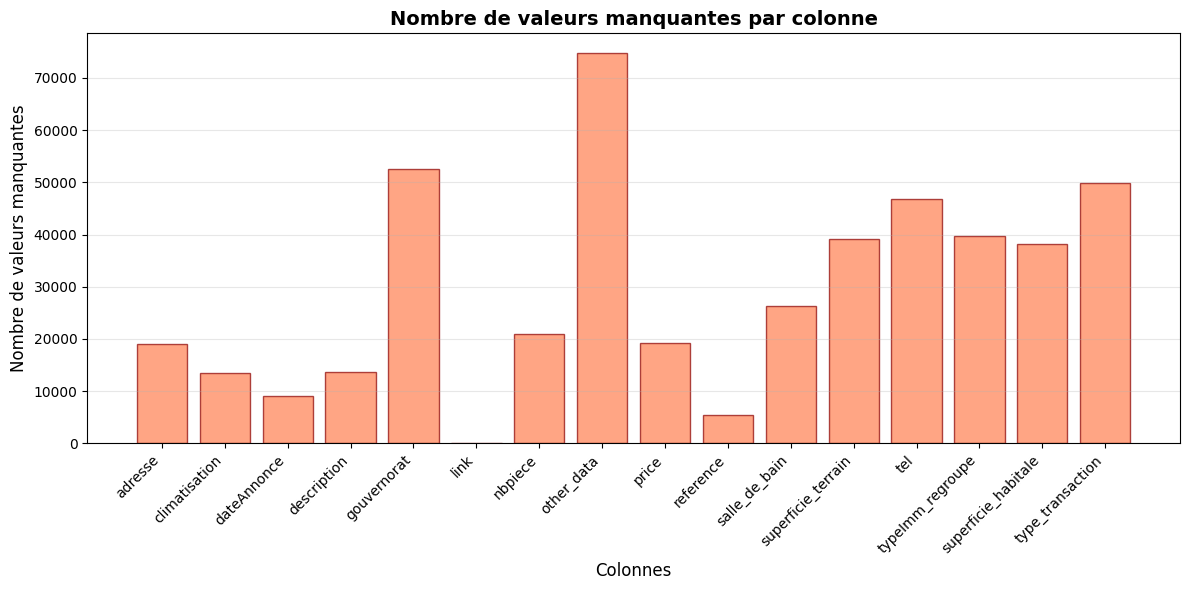

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
valeurs_manquantes = df_original.isnull().sum()
valeurs_manquantes = valeurs_manquantes[valeurs_manquantes > 0]
total_lignes = len(df_original)

# Créer le tableau
tableau_manquantes = pd.DataFrame({
    'Colonne': valeurs_manquantes.index,
    'Nb valeurs manquantes': valeurs_manquantes.values,
    'Pourcentage (%)': (valeurs_manquantes.values / total_lignes * 100).round(2)
})
tableau_manquantes = tableau_manquantes.sort_values('Nb valeurs manquantes', ascending=False)

# Afficher le tableau avec style (pour notebook)
from IPython.display import display

print("TABLEAU DES VALEURS MANQUANTES")

display(tableau_manquantes.style.background_gradient(cmap='Reds', subset=['Nb valeurs manquantes', 'Pourcentage (%)']))

# Graphique
plt.figure(figsize=(12, 6))
plt.bar(valeurs_manquantes.index, valeurs_manquantes.values, color='coral', edgecolor='darkred', alpha=0.7)
plt.xlabel('Colonnes', fontsize=12)
plt.ylabel('Nombre de valeurs manquantes', fontsize=12)
plt.title('Nombre de valeurs manquantes par colonne', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:
# ====================================================
# EXTRACTION DU GOUVERNORAT DEPUIS LA COLONNE ADRESSE
# ====================================================
import re
import pandas as pd
from tqdm import tqdm

print("\n" + "="*60)
print("EXTRACTION DU GOUVERNORAT DEPUIS LA COLONNE ADRESSE")
print("="*60)

# 1. Vérifier si la colonne adresse existe
if 'adresse' not in df_original.columns:
    print("❌ La colonne 'adresse' n'existe pas!")
    print(f"Colonnes disponibles: {list(df_original.columns)}")
else:
    # 2. Créer la colonne temporaire si elle n'existe pas
    if 'gouvernorat_adresse' not in df_original.columns:
        df_original['gouvernorat_adresse'] = None

    # 3. Fonction pour extraire le gouvernorat depuis l'adresse
    def extraire_gouvernorat_depuis_adresse(adresse):
        if pd.isna(adresse):
            return None

        text = str(adresse).lower()

        # Dictionnaire des gouvernorats tunisiens
        gouvernorats_dict = {
            'Tunis': ['tunis', 'تونس', 'tunis ville', 'tunis centre', 'el menzah', 'mutuelleville', 'belvédère', 'bardo', 'lafayette', 'ennasr', 'ennasr 2', 'ennasr 1', 'cité olympique', 'el omrane', 'el ouardia', 'bab saadoun', 'bab souika', 'halfaouine'],
            'Ariana': ['ariana', 'أريانة', 'raoued', 'soukra', 'mnihla', 'borj louzir', 'chotrana', 'douar hicher', 'sidi thabet', 'ezzahra', 'kalaat el andalous'],
            'Ben Arous': ['ben arous', 'بن عروس', 'megrine', 'mohamedia', 'radès', 'rades', 'hammam lif', 'hammam chatt', 'bou mhel', 'fouchana', 'mornag', 'el mourouj', 'bir el bey'],
            'Manouba': ['manouba', 'منوبة', 'douar hicher', 'mornaguia', 'oued ellil', 'el battan', 'borj el amri', 'den den', 'tebourba'],
            'Nabeul': ['nabeul', 'نابل', 'hammamet', 'حمامات', 'dar chaabane', 'korba', 'kelibia', 'قليبية', 'soliman', 'beni khiar', 'el maamoura', 'menzel temime', 'takelsa', 'bou argoub'],
            'Sousse': ['sousse', 'سوسة', 'msaken', 'مساكن', 'kalâa kebira', 'kalâa seghira', 'akouda', 'bouficha', 'hammam sousse', 'enfidha', 'sahloul', 'kondar', 'sidi el hani'],
            'Sfax': ['sfax', 'صفاقس', 'sakiet eddaïer', 'sakiet ezzit', 'chihia', 'bir ali ben khelifa', 'el ain', 'agra', 'mahrès', 'skhira', 'thyna', 'kerkenah'],
            'Monastir': ['monastir', 'المنستير', 'moknine', 'jemmal', 'bembla', 'ksar hellal', 'sahline', 'teboulba', 'sayada', 'lamta', 'ouerdanine'],
            'Mahdia': ['mahdia', 'المهدية', 'jebiniana', 'bou merdes', 'essouassi', 'chebba', 'salakta', 'el jam', 'hajeb el ayoun'],
            'Bizerte': ['bizerte', 'بنزرت', 'mateur', 'menzel bourguiba', 'menzel abderrahmane', 'tinja', 'sejnane', 'ras jebel', 'utique', 'ghezala', 'joumine', 'el alia', 'zarzouna', 'metline'],
            'Béja': ['béja', 'beja', 'باجة', 'testour', 'majaz al bab', 'zahret medien', 'amdoun', 'goubellat'],
            'Jendouba': ['jendouba', 'جندوبة', 'tabarka', 'ain draham', 'fernana', 'ghardimaou', 'oued mliz', 'bou slama'],
            'Le Kef': ['le kef', 'الكاف', 'el kef', 'dahmani', 'sakiet sidi youssef', 'tajerouine', 'kalaat sinan', 'jerissa'],
            'Siliana': ['siliana', 'سليانة', 'bou arada', 'gaâfour', 'kesra', 'maktar', 'rouhia', 'el krîet'],
            'Kairouan': ['kairouan', 'القيروان', 'haffouz', 'oueslatia', 'chebika', 'hajeb el ayoun', 'menzel mehiri', 'sidi amara'],
            'Kasserine': ['kasserine', 'القصرين', 'fériana', 'thala', 'sbeitla', 'jedelienne', 'haïdra', 'foussana'],
            'Sidi Bouzid': ['sidi bouzid', 'سيدي بوزيد', 'jelma', 'menzel bouzaiane', 'meknassi', 'souk jedid', 'regueb'],
            'Zaghouan': ['zaghouan', 'زغوان', 'bir mcherga', 'el fahs', 'nadhour', 'saouaf', 'zriba'],
            'Gabès': ['gabès', 'gabes', 'قابس', 'ghannouch', 'mareth', 'métouia', 'matmata', 'zrig', 'el hamma', 'chenini'],
            'Médenine': ['médenine', 'medenine', 'مدنين', 'djerba', 'جرجيس', 'zarzis', 'ben guerdane', 'houmt souk', 'midoun', 'ajim'],
            'Tataouine': ['tataouine', 'تطاوين', 'remada', 'ghomrassen', 'dehiba', 'smar', 'chenini', 'douirat'],
            'Gafsa': ['gafsa', 'قفصة', 'métlaoui', 'metlaoui', 'moularès', 'redeyef', 'sened', 'el guettar', 'belkhir'],
            'Tozeur': ['tozeur', 'توزر', 'nefta', 'degueche', 'tamerza', 'chakmou'],
            'Kébili': ['kébili', 'kebili', 'قبلي', 'douz', 'souk el ahad', 'el golâa', 'fatha', 'jemna']
        }

        # Chercher le gouvernorat dans l'adresse
        for gov, keywords in gouvernorats_dict.items():
            for keyword in keywords:
                # Patterns de recherche
                patterns = [
                    rf'\b{re.escape(keyword)}\b',  # Mot seul
                    rf'^{re.escape(keyword)}\b',   # Début de chaîne
                    rf',\s*{re.escape(keyword)}\b', # Après virgule
                    rf'\s+{re.escape(keyword)}\b',  # Espace devant
                ]
                for pattern in patterns:
                    if re.search(pattern, text, re.IGNORECASE):
                        return gov
        return None

    # 4. Appliquer l'extraction
    print("\n📌 Extraction du gouvernorat depuis la colonne 'adresse'...")
    tqdm.pandas(desc="Extraction gouvernorat")
    df_original['gouvernorat_adresse'] = df_original['adresse'].progress_apply(extraire_gouvernorat_depuis_adresse)

    nb_gouv = df_original['gouvernorat_adresse'].notna().sum()
    print(f"  ✓ {nb_gouv}/{len(df_original)} gouvernorats extraits ({nb_gouv/len(df_original)*100:.1f}%)")

    # 5. Remplir la colonne gouvernorat principale
    print("\n" + "="*60)
    print("REMPLISSAGE DE LA COLONNE GOUVERNORAT")
    print("="*60)

    avant_gov = df_original['gouvernorat'].notna().sum() if 'gouvernorat' in df_original.columns else 0

    if 'gouvernorat' not in df_original.columns:
        df_original['gouvernorat'] = None

    df_original['gouvernorat'] = df_original['gouvernorat'].fillna(df_original['gouvernorat_adresse'])
    apres_gov = df_original['gouvernorat'].notna().sum()

    print(f"  gouvernorat: {avant_gov} → {apres_gov} (+{apres_gov - avant_gov})")

    # 6. Supprimer la colonne temporaire (optionnel)
    print("\n🗑️ Suppression de la colonne temporaire...")
    df_original = df_original.drop(columns=['gouvernorat_adresse'], errors='ignore')
    print("  ✓ gouvernorat_adresse supprimée")

    # 7. Aperçu des résultats
    print("\n📝 APERÇU DES RÉSULTATS (10 premières lignes):")
    cols_affichage = ['adresse', 'gouvernorat']
    cols_exist = [c for c in cols_affichage if c in df_original.columns]
    if cols_exist:
        for i in range(min(10, len(cv))):
            print(f"\n--- LIGNE {i+1} ---")
            print(f"Adresse: {str(df_original['adresse'].iloc[i])[:100]}...")
            print(f"Gouvernorat extrait: {df_original['gouvernorat'].iloc[i]}")

    # 8. Statistiques
    print("\n📊 STATISTIQUES FINALES:")
    print(f"  Total lignes: {len(df_original)}")
    print(f"  Gouvernorats extraits: {df_original['gouvernorat'].notna().sum()}")
    print(f"  Taux de couverture: {df_original['gouvernorat'].notna().sum()/len(df_original)*100:.1f}%")

    if df_original['gouvernorat'].notna().sum() > 0:
        print("\n📋 Distribution des gouvernorats extraits:")
        print(df_original['gouvernorat'].value_counts().head(10))




EXTRACTION DU GOUVERNORAT DEPUIS LA COLONNE ADRESSE

📌 Extraction du gouvernorat depuis la colonne 'adresse'...


Extraction gouvernorat: 100%|██████████| 77826/77826 [06:21<00:00, 203.92it/s]

  ✓ 48556/77826 gouvernorats extraits (62.4%)

REMPLISSAGE DE LA COLONNE GOUVERNORAT
  gouvernorat: 25276 → 56395 (+31119)

🗑️ Suppression de la colonne temporaire...
  ✓ gouvernorat_adresse supprimée

📝 APERÇU DES RÉSULTATS (10 premières lignes):


NameError: name 'cv' is not defined

TABLEAU DES VALEURS MANQUANTES


,Colonne,Nb valeurs manquantes,Pourcentage (%)
7,other_data,74807,96.120000
15,type_transaction,49864,64.070000
12,tel,46822,60.160000
13,typeImm_regroupe,39812,51.160000
11,superficie_terrain,39123,50.270000
14,superficie_habitale,38241,49.140000
10,salle_de_bain,26369,33.880000
4,gouvernorat,21431,27.540000
6,nbpiece,20882,26.830000
8,price,19245,24.730000


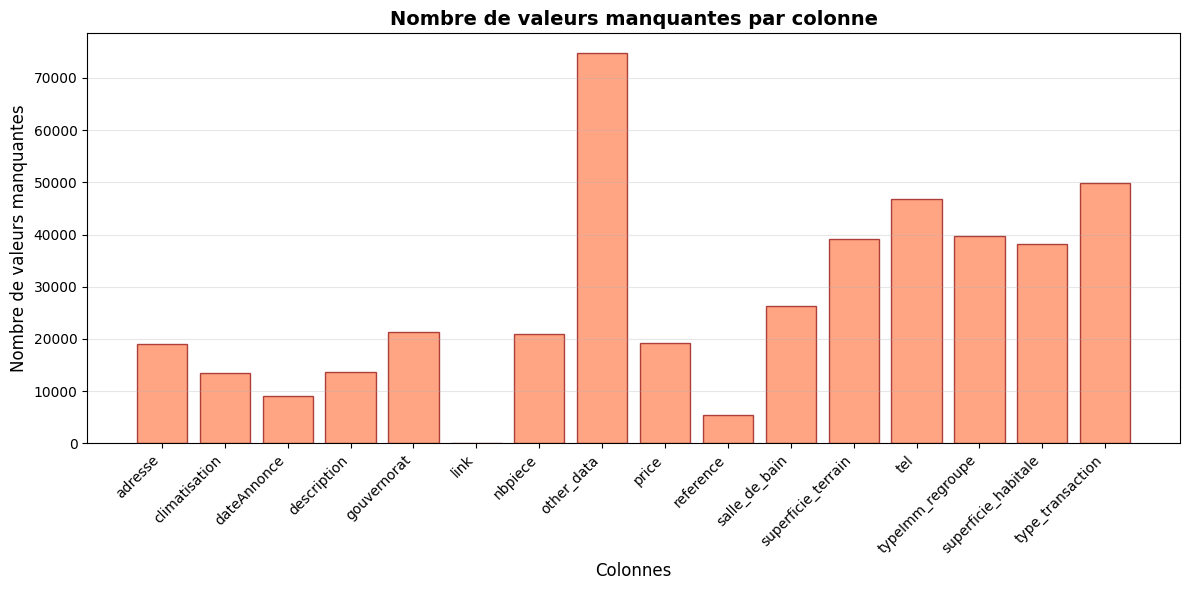

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
valeurs_manquantes = df_original.isnull().sum()
valeurs_manquantes = valeurs_manquantes[valeurs_manquantes > 0]
total_lignes = len(df_original)

# Créer le tableau
tableau_manquantes = pd.DataFrame({
    'Colonne': valeurs_manquantes.index,
    'Nb valeurs manquantes': valeurs_manquantes.values,
    'Pourcentage (%)': (valeurs_manquantes.values / total_lignes * 100).round(2)
})
tableau_manquantes = tableau_manquantes.sort_values('Nb valeurs manquantes', ascending=False)

# Afficher le tableau avec style (pour notebook)
from IPython.display import display

print("TABLEAU DES VALEURS MANQUANTES")

display(tableau_manquantes.style.background_gradient(cmap='Reds', subset=['Nb valeurs manquantes', 'Pourcentage (%)']))

# Graphique
plt.figure(figsize=(12, 6))
plt.bar(valeurs_manquantes.index, valeurs_manquantes.values, color='coral', edgecolor='darkred', alpha=0.7)
plt.xlabel('Colonnes', fontsize=12)
plt.ylabel('Nombre de valeurs manquantes', fontsize=12)
plt.title('Nombre de valeurs manquantes par colonne', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:

# 4. Sauvegarder
df_original.to_excel('cv_clean.xlsx', index=False)
print("\n✅ Fichier sauvegardé: cv_clean.xlsx")


✅ Fichier sauvegardé: cv_clean.xlsx
